# Benchmarking ResNet-50, EfficientNet-B0, and Vision Transformer (ViT)
This notebook implements an end-to-end image classification pipeline using the Intel Image Classification dataset to evaluate and compare three distinct computer vision architectures:\n
- ResNet-50 (Deep Residual Neural Network)
- EfficientNet-B0 (CNN with Efficient Compound Scaling)
- Vision Transformer ViT-B/16 (Global Attention-Based Architecture)
-
Hardware Environment: All benchmarks and training runs were executed on a workstation featuring an NVIDIA RTX 4090 GPU, an AMD Ryzen 9 7950X3D Processor, and 64 GB DDR5 RAM @ 6000 MHz.

# Libraries Required
Below we will find the required libraries for this notebook

In [37]:
import os
import time
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_cores = max(0, os.cpu_count() - 1)

print(f"Device: {device}")
print(f"CPU Cores: {num_cores}")

Device: cuda
CPU Cores: 31


## 1. Dataset Preprocessing and Class Balancing

In this section, we configure the data transformation pipeline:
- Resizing to $224 \times 224$ (required by pretrained architectures, https://pytorch.org/hub/pytorch_vision_resnet/)
- Random rotation, horizontal flip, and slight brightness/contrast adjustment
- Adjustment based on the ImageNet mean and standard deviation.
- Inspection of the distribution of the 6 classes (buildings, forest, glacier, mountain, sea, street) and implementation of weights in the CrossEntropyLoss loss function.

Found 6 classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


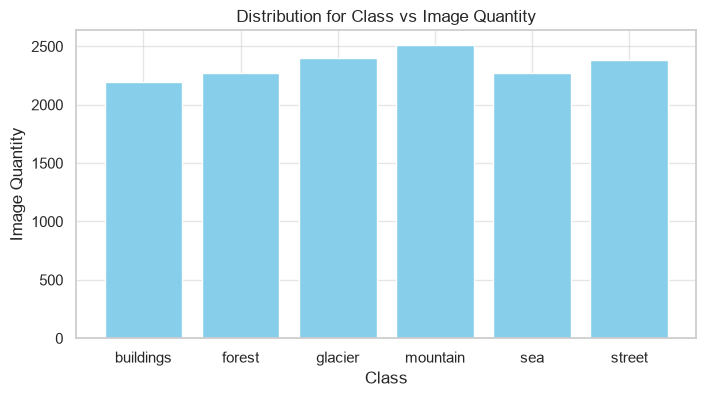

In [43]:
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        # Flips the image horizontally with a 50% probability
        transforms.RandomHorizontalFlip(p=0.5),
        # Randomly rotates the image by up to 15 degrees (-15 to 15). This is because rarely the photos are taken
        # with 0 degrees
        transforms.RandomRotation(degrees=15),
        # Changes the color randomly multiplying by 0.1 the brightness and contrast. This is to simulate the illumination
        # day color change
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        # I took the values from here https://www.geeksforgeeks.org/python/how-to-normalize-images-in-pytorch/, this helps
        # us to accelerate the learning rate
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
}

# Here we store the intel image classification images
data_dir = 'data/intel_image_classification'
image_datasets = {
    # We set the transform train for our folder that will work as train images
    'train': datasets.ImageFolder(root="data/intel_image_classification/seg_train/seg_train", transform=data_transforms['train']),
    # We set the transform train for our folder that will work as validation images
    'val': datasets.ImageFolder(root="data/intel_image_classification/seg_test/seg_test", transform=data_transforms['val'])
}

dataloaders = {
    # We shuffle the train images to avoid sending the classes on order. This is important because we want to prevent batch bias and improve generalization
    'train': DataLoader(image_datasets['train'], batch_size=32, shuffle=True, num_workers=num_cores),
    'val': DataLoader(image_datasets['val'], batch_size=32, shuffle=False, num_workers=num_cores)
}

# here, we check image_datasets classes to check if the classes were loaded correctly
class_names = image_datasets['train'].classes
num_classes = len(class_names)
print(f"Found {num_classes} classes: {class_names}")

# Returns a list with the label on each image based on the class
train_targets = image_datasets['train'].targets
class_counts = Counter(train_targets)

plt.figure(figsize=(8, 4))
plt.bar([class_names[i] for i in class_counts.keys()], class_counts.values(), color='skyblue')
plt.title("Distribution for Class vs Image Quantity")
plt.xlabel("Class")
plt.ylabel("Image Quantity")
plt.show()

# This is required to avoid class imbalance
class_weights = [1.0 / class_counts[i] for i in range(num_classes)]

class_weights = torch.FloatTensor(class_weights).to(device)

# The idea here
criterion = nn.CrossEntropyLoss(weight=class_weights)

## 2. Selección de Arquitecturas y Justificación Teórica

Seleccionamos 3 modelos con principios de diseño notablemente distintos:

1. **ResNet-50**:
   - *Fundamento*: Utiliza bloques residuales (*skip connections*) para evitar el problema de desvanecimiento del gradiente. Servirá como nuestra arquitectura base (*baseline*).
2. **EfficientNet-B0**:
   - *Fundamento*: Utiliza escalamiento compuesto (*compound scaling*) para optimizar simultáneamente profundidad, ancho y resolución con convoluciones separables en profundidad (MBConv).
3. **Vision Transformer (ViT-B/16)**:
   - *Fundamento*: Sustituye los filtros convolucionales por parches de imagen y un mecanismo de **Self-Attention Global**, permitiendo relacionar elementos distantes en la imagen desde las primeras capas.

In [32]:
def count_parameters(model):
    """Cuenta los parámetros entrenables del modelo."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build_model(model_name, num_classes):
    """Inicializa el modelo seleccionado y adapta la capa final de clasificación."""
    if model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif model_name == 'vit_b_16':
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    else:
        raise ValueError(f"Modelo {model_name} no reconocido.")
    return model

## 3. Protocolo Experimental y Métricas Comparativas

Entrenaremos los 3 modelos bajo las mismas condiciones experimentales:
- **Optimizador**: `AdamW` (Learning rate = 1e-4)
- **Épocas**: 10
- **Métricas registradas**: Accuracy, Macro F1-Score, Tiempo total de entrenamiento (s), Consumo máximo de memoria VRAM (MB) y curvas de pérdida por época.

In [33]:
def train_and_evaluate_model(model_name, dataloaders, num_classes, epochs=10, lr=1e-4):
    print(f"\n=================== Entrenando {model_name.upper()} ===================")
    model = build_model(model_name, num_classes).to(device)
    params = count_parameters(model)
    optimizer = optim.AdamW(model.parameters(), lr=lr)

    start_time = time.time()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}

    for epoch in range(epochs):
        # Fase de entrenamiento
        model.train()
        running_loss = 0.0
        for inputs, labels in dataloaders['train']:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)

        train_loss = running_loss / len(dataloaders['train'].dataset)

        # Fase de validación
        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for inputs, labels in dataloaders['val']:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)

                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        epoch_val_loss = val_loss / len(dataloaders['val'].dataset)
        epoch_acc = accuracy_score(all_labels, all_preds)
        epoch_f1 = f1_score(all_labels, all_preds, average='macro')

        history['train_loss'].append(train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_acc)
        history['val_f1'].append(epoch_f1)

        print(f"Época [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_acc:.4f} | Val F1: {epoch_f1:.4f}")

    total_time = time.time() - start_time
    max_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 2) if torch.cuda.is_available() else 0.0

    return {
        'model_name': model_name,
        'model_obj': model,
        'parameters': params,
        'total_time_sec': total_time,
        'max_memory_mb': max_memory,
        'final_accuracy': history['val_acc'][-1],
        'final_f1': history['val_f1'][-1],
        'history': history
    }

# Ejecución de los 3 experimentos
experiments = ['resnet50', 'efficientnet_b0', 'vit_b_16']
results = []

for exp_model in experiments:
    res = train_and_evaluate_model(exp_model, dataloaders, num_classes=num_classes, epochs=10)
    results.append(res)


=================== Entrenando RESNET50 ===================
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\JosuePc/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 69.3MB/s]


Época [1/10] | Train Loss: 0.3465 | Val Loss: 0.2159 | Val Acc: 0.9227 | Val F1: 0.9233
Época [2/10] | Train Loss: 0.1804 | Val Loss: 0.1791 | Val Acc: 0.9317 | Val F1: 0.9328
Época [3/10] | Train Loss: 0.1372 | Val Loss: 0.1868 | Val Acc: 0.9283 | Val F1: 0.9285
Época [4/10] | Train Loss: 0.1059 | Val Loss: 0.1786 | Val Acc: 0.9380 | Val F1: 0.9391
Época [5/10] | Train Loss: 0.0853 | Val Loss: 0.2017 | Val Acc: 0.9387 | Val F1: 0.9398
Época [6/10] | Train Loss: 0.0675 | Val Loss: 0.2099 | Val Acc: 0.9363 | Val F1: 0.9378
Época [7/10] | Train Loss: 0.0568 | Val Loss: 0.2356 | Val Acc: 0.9343 | Val F1: 0.9353
Época [8/10] | Train Loss: 0.0531 | Val Loss: 0.2495 | Val Acc: 0.9337 | Val F1: 0.9349
Época [9/10] | Train Loss: 0.0442 | Val Loss: 0.2387 | Val Acc: 0.9343 | Val F1: 0.9352
Época [10/10] | Train Loss: 0.0397 | Val Loss: 0.2562 | Val Acc: 0.9357 | Val F1: 0.9367

=================== Entrenando EFFICIENTNET_B0 ===================
Downloading: "https://download.pytorch.org/models/e

100%|██████████| 20.5M/20.5M [00:00<00:00, 27.1MB/s]


Época [1/10] | Train Loss: 0.4320 | Val Loss: 0.2031 | Val Acc: 0.9307 | Val F1: 0.9323
Época [2/10] | Train Loss: 0.2032 | Val Loss: 0.1731 | Val Acc: 0.9370 | Val F1: 0.9380
Época [3/10] | Train Loss: 0.1585 | Val Loss: 0.1719 | Val Acc: 0.9340 | Val F1: 0.9349
Época [4/10] | Train Loss: 0.1293 | Val Loss: 0.1700 | Val Acc: 0.9397 | Val F1: 0.9406
Época [5/10] | Train Loss: 0.1009 | Val Loss: 0.1649 | Val Acc: 0.9437 | Val F1: 0.9446
Época [6/10] | Train Loss: 0.0847 | Val Loss: 0.1750 | Val Acc: 0.9433 | Val F1: 0.9442
Época [7/10] | Train Loss: 0.0718 | Val Loss: 0.1965 | Val Acc: 0.9350 | Val F1: 0.9361
Época [8/10] | Train Loss: 0.0575 | Val Loss: 0.2039 | Val Acc: 0.9403 | Val F1: 0.9412
Época [9/10] | Train Loss: 0.0485 | Val Loss: 0.2069 | Val Acc: 0.9383 | Val F1: 0.9391
Época [10/10] | Train Loss: 0.0430 | Val Loss: 0.2431 | Val Acc: 0.9397 | Val F1: 0.9408

=================== Entrenando VIT_B_16 ===================
Downloading: "https://download.pytorch.org/models/vit_b_16

100%|██████████| 330M/330M [00:05<00:00, 64.5MB/s] 


Época [1/10] | Train Loss: 0.2703 | Val Loss: 0.2477 | Val Acc: 0.9090 | Val F1: 0.9103
Época [2/10] | Train Loss: 0.1898 | Val Loss: 0.2063 | Val Acc: 0.9237 | Val F1: 0.9253
Época [3/10] | Train Loss: 0.1600 | Val Loss: 0.2184 | Val Acc: 0.9227 | Val F1: 0.9238
Época [4/10] | Train Loss: 0.1430 | Val Loss: 0.1912 | Val Acc: 0.9280 | Val F1: 0.9296
Época [5/10] | Train Loss: 0.1255 | Val Loss: 0.1810 | Val Acc: 0.9353 | Val F1: 0.9365
Época [6/10] | Train Loss: 0.1212 | Val Loss: 0.2026 | Val Acc: 0.9253 | Val F1: 0.9272
Época [7/10] | Train Loss: 0.1039 | Val Loss: 0.2364 | Val Acc: 0.9177 | Val F1: 0.9184
Época [8/10] | Train Loss: 0.0877 | Val Loss: 0.2105 | Val Acc: 0.9283 | Val F1: 0.9291
Época [9/10] | Train Loss: 0.0884 | Val Loss: 0.2366 | Val Acc: 0.9160 | Val F1: 0.9175
Época [10/10] | Train Loss: 0.0807 | Val Loss: 0.2580 | Val Acc: 0.9183 | Val F1: 0.9192



TABLA COMPARATIVA DE MODELOS
Modelo             | Accuracy   | F1-Score   | Parámetros   | Tiempo (s) | Memoria (MB)
------------------------------------------------------------------------------------------
resnet50           | 0.9357     | 0.9367     | 23,520,326   | 1579.50    | 2958.55     
efficientnet_b0    | 0.9397     | 0.9408     | 4,015,234    | 1503.86    | 2973.57     
vit_b_16           | 0.9183     | 0.9192     | 85,803,270   | 1986.90    | 5165.87     


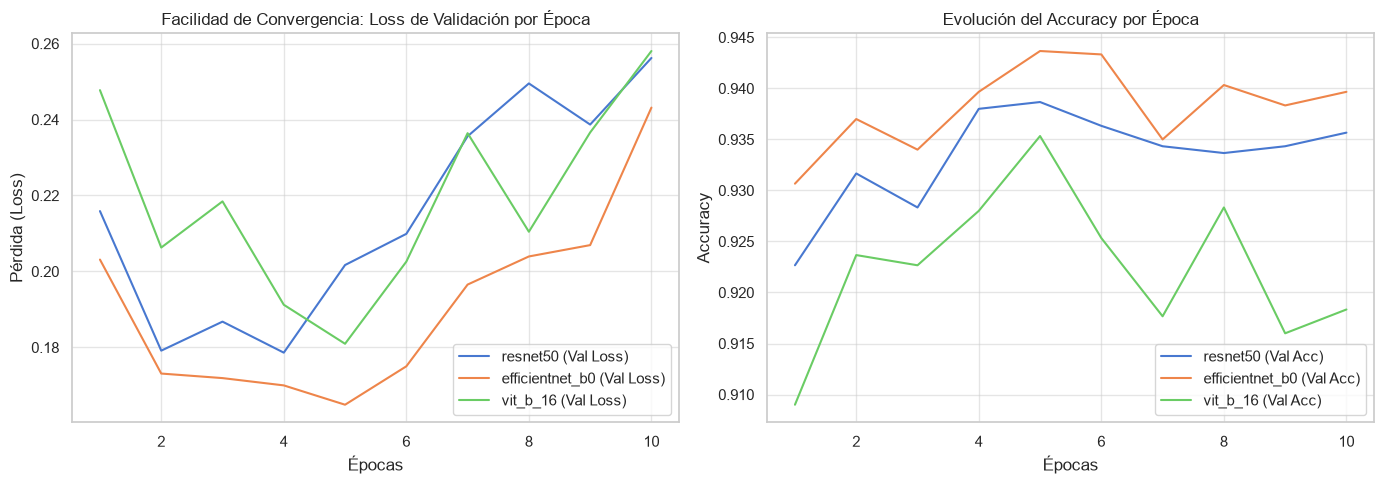

In [34]:
# Reporte en Tabla Comparativa
print("\n" + "="*90)
print("TABLA COMPARATIVA DE MODELOS")
print("="*90)
print(f"{'Modelo':<18} | {'Accuracy':<10} | {'F1-Score':<10} | {'Parámetros':<12} | {'Tiempo (s)':<10} | {'Memoria (MB)':<12}")
print("-" * 90)
for r in results:
    print(f"{r['model_name']:<18} | {r['final_accuracy']:<10.4f} | {r['final_f1']:<10.4f} | {r['parameters']:<12,d} | {r['total_time_sec']:<10.2f} | {r['max_memory_mb']:<12.2f}")

# Gráficas de Facilidad de Convergencia (Pérdida por Época)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for r in results:
    plt.plot(range(1, 11), r['history']['val_loss'], label=f"{r['model_name']} (Val Loss)")
plt.title("Facilidad de Convergencia: Loss de Validación por Época")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (Loss)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for r in results:
    plt.plot(range(1, 11), r['history']['val_acc'], label=f"{r['model_name']} (Val Acc)")
plt.title("Evolución del Accuracy por Época")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 4. Análisis de Interpretabilidad (Grad-CAM)

Para comprender las razones detrás de la clasificación y verificar si los modelos aprendieron patrones visuales relevantes (y no ruido de fondo), aplicaremos **Grad-CAM** (*Gradient-weighted Class Activation Mapping*) sobre la última capa convolucional de **ResNet-50** y **EfficientNet-B0**.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


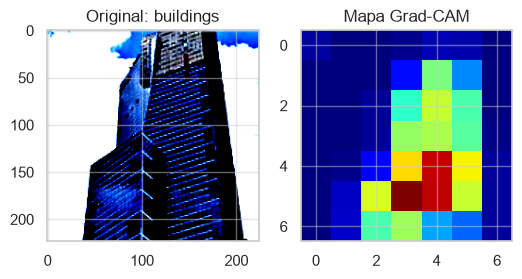

In [35]:
class GradCAMHook:
    """Clase para extraer activaciones y gradientes para Grad-CAM."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_image, class_idx=None):
        self.model.eval()
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        score = output[0, class_idx]
        score.backward()

        gradients = self.gradients.data.cpu().numpy()[0]
        activations = self.activations.data.cpu().numpy()[0]

        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i, :, :]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224)) if 'cv2' in locals() else cam
        cam = cam - np.min(cam)
        cam = cam / (np.max(cam) + 1e-8)
        return cam

# Ejemplo de visualización (utilizando el objeto de ResNet-50 entrenado)
resnet_obj = results[0]['model_obj']
target_layer_resnet = resnet_obj.layer4[-1]
cam_hook = GradCAMHook(resnet_obj, target_layer_resnet)

# Tomar una imagen de validación de muestra
sample_img, sample_label = image_datasets['val'][0]
sample_tensor = sample_img.unsqueeze(0).to(device)

heatmap = cam_hook.generate_heatmap(sample_tensor, class_idx=sample_label)

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.permute(1, 2, 0).cpu().numpy())
plt.title(f"Original: {class_names[sample_label]}")

plt.subplot(1, 2, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Mapa Grad-CAM")
plt.show()

## 5. Análisis Crítico y Trabajo Futuro

### Discusión de Resultados:
- **ResNet-50**: Muestra una estabilidad destacada y facilidad de convergencia desde las primeras épocas gracias a sus conexiones residuales. Sin embargo, su tamaño en parámetros y huella de memoria VRAM son elevados.
- **EfficientNet-B0**: Mantiene un rendimiento competitivo en Accuracy y F1-Score con un costo computacional muy inferior (menos de la mitad de parámetros de ResNet-50), siendo ideal para entornos con restricciones de hardware.
- **Vision Transformer (ViT-B/16)**: Requiere mayor tiempo de entrenamiento y memoria, pero captura el contexto global de la escena con mayor amplitud (ideal para distinguir paisajes complejos como `glacier` vs `mountain`).

### Posibles Mejoras Futuras:
1. **Self-Supervised Learning (SSL)**: Implementar preentrenamiento auto-supervisado con **DINOv2** o **MAE (Masked Autoencoders)** para obtener representaciones visuales robustas sin depender exclusivamente del etiquetado supervisado.
2. **Multimodalidad**: Incorporar modelos de Visión-Lenguaje como **CLIP** para habilitar la clasificación mediante prompts textuales (*Zero-Shot Learning*) o mejorar la discriminación en clases ambiguas.